# Practical Session 11a &mdash; PCA, LDA and the matrix factorizations

**Companion to Lecture&nbsp;11.** First of two notebooks for Session&nbsp;11.

| # | Notebook | Topic |
|---|----------|-------|
| **11a** | **PCA, LDA and the factorizations** | **the linear methods: PCA, LDA, factor analysis, NMF (this notebook)** |
| 11b | t-SNE and UMAP | the nonlinear methods: kernel PCA, t-SNE, UMAP &mdash; and why their maps must be read carefully |

Session&nbsp;10 grouped the **rows** of the data matrix. This session compresses its **columns**:
which few *combinations* of features carry the signal.

**The thread of this notebook: variance is not always the question you are asking.**
Section&nbsp;1 says why we bother reducing at all. Sections&nbsp;2&ndash;5 build PCA, which answers
one question superbly well &mdash; *where does the data spread out?* Then we break it three times,
and each break turns out to be a **different question** about the very same matrix.

| section | the question you were actually asking | what answers it |
|---|---|---|
| 1 | is a hundred features really a problem? | the **curse of dimensionality** |
| 2&ndash;5 | where does the data spread out? | **PCA** |
| 6&ndash;7 | which direction separates the *classes*? | **LDA** &mdash; it sees $y$, and PCA cannot |
| 8&ndash;9 | which spread is shared, and which is one feature's own noise? | **factor analysis** &mdash; a per-feature $\Psi$ |
| 10 | which non-negative *parts* add up to this? | **NMF** &mdash; nothing may cancel |

> &#11088; **Key idea.** PCA is a rotation that keeps the high-variance coordinates and throws the
> rest away. Every number it produces &mdash; the components, the variances, the reconstruction
> error &mdash; is an eigenvalue or an eigenvector of one $d\times d$ matrix, and you can check the
> whole thing on four points by hand.

> &#9888;&#65039; **One rule for this whole notebook.** A component $\mathbf{v}$ and $-\mathbf{v}$
> are the *same* direction: the sign is arbitrary and solvers pick it however they like. So we
> never compare components by subtracting them. We compare **directions**, with
> $|\cos\theta|$ and the angle between them.

*Run each cell (Shift+Enter). Self-contained and offline.*

In [1]:
import math

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer, load_digits
from sklearn.decomposition import NMF, PCA, FactorAnalysis
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis as QDA
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_score)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from scipy.linalg import eigh

from nb_utils import use_style
from nb_data import make_cigars, best_1d_threshold_accuracy

use_style("notes")
C0, C1, CG, CN = "#0072B2", "#D55E00", "#009E73", "#E69F00"
CP, CX = "#CC79A7", "0.62"
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=[C0, C1, CG, CN, CP])   # frozen palette


def unit(v):
    "v rescaled to length 1"
    v = np.asarray(v, dtype=float)
    return v / np.linalg.norm(v)


def direction_angle_deg(a, b):
    "angle between two DIRECTIONS in degrees -- sign-blind, since -v spans the same line"
    return float(np.degrees(np.arccos(min(1.0, abs(unit(a) @ unit(b))))))


print("ready")

ready


## 1. Why reduce at all: the curse of dimensionality

Before any method, the motivation. Scatter $100$ points along a line of length one and they sit
about $0.01$ apart, elbow to elbow. Ask for that same spacing inside a ten-dimensional unit cube
and you need $100^{10}$ points &mdash; the cell prints the number. With the hundred you actually
have, the cube is essentially empty.

The symptom you can measure is what happens to **distances**. Draw $n$ uniform points in a
$d$-cube, pick a query point, and compare its nearest neighbor to its farthest:

$$r(d)=\mathbb{E}\!\left[\frac{\min_i\lVert \mathbf{q}-\mathbf{x}_i\rVert}
{\max_i\lVert \mathbf{q}-\mathbf{x}_i\rVert}\right].$$

In one dimension $r$ is tiny &mdash; the nearest point is hundreds of times closer than the
farthest, so "nearest neighbor" means something. As $d$ grows, $r$ climbs toward $1$ and that
contrast drains away.

**Be careful how far you push this.** You will read that in high dimensions "all points are
equidistant". At the sizes you actually work with, that is an exaggeration, and the table below
says by how much: with $n=500$ points, $r=0.616$ at $d=50$ &mdash; the nearest point is still
$62\%$ as far as the farthest, so the farthest is only $1.62\times$ farther. Distances **flatten**;
they do not become equal. Even at $d=200$ the factor is $1.27$. That is enough to hurt a
nearest-neighbor method and enough to motivate reducing $d$ &mdash; which is all the curse has to
prove.

500 uniform points in the unit cube, 40 query points, 10 draws each

   d | nearest / farthest | the farthest point is this much farther
   1 |   0.001 +/- 0.000    |  718.47x
   2 |   0.022 +/- 0.002    |  45.13x
   3 |   0.061 +/- 0.003    |  16.38x
   5 |   0.141 +/- 0.006    |  7.09x
  10 |   0.293 +/- 0.006    |  3.41x
  20 |   0.450 +/- 0.005    |  2.22x
  50 |   0.616 +/- 0.005    |  1.62x
 100 |   0.715 +/- 0.004    |  1.40x
 200 |   0.788 +/- 0.003    |  1.27x

still climbing at d = 200: distances FLATTEN, they do not become equal
to pack 100 points in a 10-cube as tightly as 100 points on a line: 100**10 = 1e+20 points


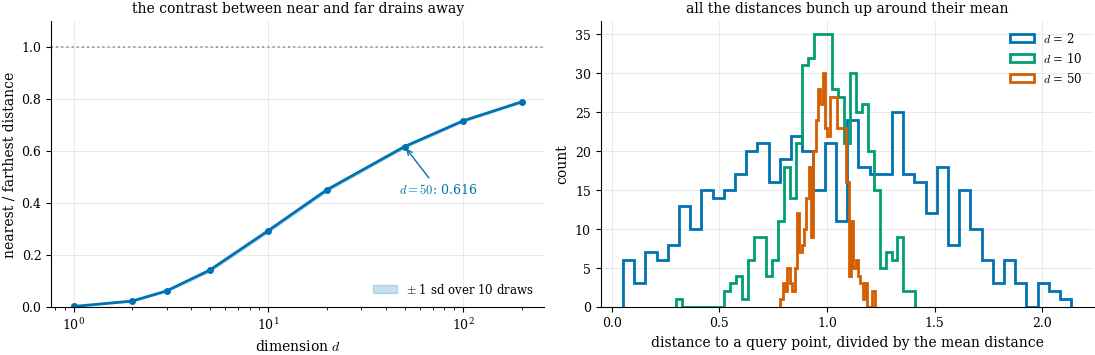

In [2]:
rng_cd = np.random.default_rng(0)
dims_cd = np.array([1, 2, 3, 5, 10, 20, 50, 100, 200])     # <-- CHANGE ME
n_cd, q_cd, rep_cd = 500, 40, 10                           # points, queries, repeats

mean_cd, sd_cd = [], []
for d in dims_cd:
    per_draw = []
    for _ in range(rep_cd):
        Xq = rng_cd.random((n_cd, d))
        Qq = rng_cd.random((q_cd, d))
        D = np.sqrt(((Qq[:, None, :] - Xq[None, :, :]) ** 2).sum(-1))
        per_draw.append(np.mean(D.min(axis=1) / D.max(axis=1)))
    mean_cd.append(np.mean(per_draw))
    sd_cd.append(np.std(per_draw))
mean_cd, sd_cd = np.array(mean_cd), np.array(sd_cd)

print(f"{n_cd} uniform points in the unit cube, {q_cd} query points, {rep_cd} draws each\n")
print("   d | nearest / farthest | the farthest point is this much farther")
for d, m, s in zip(dims_cd, mean_cd, sd_cd):
    print(f" {d:3d} |   {m:.3f} +/- {s:.3f}    |  {1/m:.2f}x")
print(f"\nstill climbing at d = {dims_cd[-1]}: distances FLATTEN, they do not become equal")
print(f"to pack 100 points in a 10-cube as tightly as 100 points on a line: "
      f"100**10 = {100 ** 10:.0e} points")

# the same effect seen as a distribution: every distance from one query point
d_show = (2, 10, 50)
fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(11.0, 3.6))
ax_l.semilogx(dims_cd, mean_cd, "-o", color=C0, ms=4, lw=2.0)
ax_l.fill_between(dims_cd, mean_cd - sd_cd, mean_cd + sd_cd, color=C0, alpha=0.22,
                  label=f"$\\pm$ 1 sd over {rep_cd} draws")
ax_l.axhline(1.0, ls=":", color=CX, lw=1.4)
ax_l.annotate(f"$d=50$: {mean_cd[dims_cd == 50][0]:.3f}", xy=(50, mean_cd[dims_cd == 50][0]),
              xytext=(-4, -34), textcoords="offset points", fontsize=9, color=C0,
              arrowprops=dict(arrowstyle="->", color=C0, lw=1.0))
ax_l.set_xlabel("dimension $d$"); ax_l.set_ylabel("nearest / farthest distance")
ax_l.set_ylim(0, 1.1); ax_l.legend(fontsize=8.5, loc="lower right")
ax_l.set_title("the contrast between near and far drains away", fontsize=10)

for d, col in zip(d_show, (C0, CG, C1)):
    Xq = rng_cd.random((n_cd, d))
    dd = np.sqrt(((Xq - rng_cd.random(d)) ** 2).sum(axis=1))
    ax_r.hist(dd / dd.mean(), bins=40, histtype="step", lw=2.0, color=col, label=f"$d$ = {d}")
ax_r.set_xlabel("distance to a query point, divided by the mean distance")
ax_r.set_ylabel("count"); ax_r.legend(fontsize=8.5)
ax_r.set_title("all the distances bunch up around their mean", fontsize=10)
plt.show()

## 2. All of PCA, on four points

PCA takes three steps, and on the right four points every one of them comes out as a whole number.

$$\mathbf{X}=\begin{pmatrix}7&5\\3&1\\6&2\\4&4\end{pmatrix}
\quad\Rightarrow\quad \boldsymbol\mu=(5,3),\qquad
\tilde{\mathbf{X}}=\begin{pmatrix}2&2\\-2&-2\\1&-1\\-1&1\end{pmatrix}$$

1. **Center**: subtract the mean.
2. **Covariance**: $C=\tfrac1n\tilde{\mathbf{X}}^\top\tilde{\mathbf{X}}$. Here the sums are
   $\sum x^2=10$, $\sum xy=6$, $\sum y^2=10$ over $n=4$ points, so
   $C=\begin{pmatrix}2.5&1.5\\1.5&2.5\end{pmatrix}$.
3. **Eigendecompose**: $\det(C-\lambda I)=(2.5-\lambda)^2-1.5^2=0$ gives $\lambda=4$ and $\lambda=1$,
   with $v_1\propto(1,1)$ and $v_2\propto(1,-1)$ &mdash; the same little characteristic equation the
   lecture solved for $\left(\begin{smallmatrix}2&1\\1&2\end{smallmatrix}\right)$.

PC1 therefore explains $4/(4+1)=80\%$ of the variance. The SVD of the *centered* matrix gives the
same thing through a different door: $\tilde{\mathbf{X}}=U\Sigma V^\top$ with $\sigma=(4,2)$, and
$\sigma_k^2/n=(4,1)=\lambda_k$.

> &#9888;&#65039; **The factor everyone trips over.** The lecture divides by $n$; `numpy.cov` and
> scikit-learn divide by $n-1$. So `pca.explained_variance_` is $\sigma_k^2/(n-1)$, which here is
> $(16/3,\,4/3)=(5.333,\,1.333)$, not $(4,1)$. The *ratios* are identical, so nothing you do with
> `explained_variance_ratio_` is affected &mdash; but the eigenvalues themselves differ by
> $n/(n-1)$, and on four points that is a factor of $1.333$.

In [3]:
X4 = np.array([[7.0, 5.0], [3.0, 1.0], [6.0, 2.0], [4.0, 4.0]])
n4 = len(X4)
Xc4 = X4 - X4.mean(axis=0)                      # step 1: center. the mean is (5, 3)
C_pop4 = Xc4.T @ Xc4 / n4                       # step 2: the 1/n covariance of the lecture
lam4, V4 = np.linalg.eigh(C_pop4)               # step 3: eigendecompose
ord4 = np.argsort(lam4)[::-1]
lam4, V4 = lam4[ord4], V4[:, ord4]
sig4 = np.linalg.svd(Xc4, compute_uv=False)     # the same answer via the SVD
p4 = PCA().fit(X4)

print("centered rows\n", Xc4)
print(f"\nC = X~' X~ / n           {C_pop4.tolist()}")
print(f"eigenvalues of C         {lam4.round(10)}          <- 4 and 1, exactly")
print(f"PC1, PC2                 {unit(V4[:, 0]).round(6)}  {unit(V4[:, 1]).round(6)}")
print(f"explained-variance ratio {(lam4 / lam4.sum()).round(10)}")
print(f"\nsingular values of X~    {sig4.round(10)}          <- 4 and 2, exactly")
print(f"sigma^2 / n              {(sig4 ** 2 / n4).round(10)}          = the eigenvalues above")
print(f"sigma^2 / (n-1)          {(sig4 ** 2 / (n4 - 1)).round(6)}")
print(f"sklearn explained_var_   {p4.explained_variance_.round(6)}   <- sklearn divides by n-1")
print(f"sklearn EVR              {p4.explained_variance_ratio_.round(10)}   <- the RATIO is the same")
print(f"angles to sklearn's PCs  {direction_angle_deg(V4[:, 0], p4.components_[0]):.1e} deg,"
      f" {direction_angle_deg(V4[:, 1], p4.components_[1]):.1e} deg")

centered rows
 [[ 2.  2.]
 [-2. -2.]
 [ 1. -1.]
 [-1.  1.]]

C = X~' X~ / n           [[2.5, 1.5], [1.5, 2.5]]
eigenvalues of C         [4. 1.]          <- 4 and 1, exactly
PC1, PC2                 [0.707107 0.707107]  [-0.707107  0.707107]
explained-variance ratio [0.8 0.2]

singular values of X~    [4. 2.]          <- 4 and 2, exactly
sigma^2 / n              [4. 1.]          = the eigenvalues above
sigma^2 / (n-1)          [5.333333 1.333333]
sklearn explained_var_   [5.333333 1.333333]   <- sklearn divides by n-1
sklearn EVR              [0.8 0.2]   <- the RATIO is the same
angles to sklearn's PCs  0.0e+00 deg, 0.0e+00 deg


## 3. Two definitions, one answer

The lecture gave PCA twice:

* **maximize** the variance of the projections onto a direction $\mathbf{u}$;
* **minimize** the squared *perpendicular* distance from the points to the line through
  $\mathbf{u}$.

They sound like different fits. They are the same fit, and the reason is Pythagoras: for a unit
$\mathbf{u}$, every centered point splits into a piece along the line and a piece across it,

$$\lVert\tilde{\mathbf{x}}\rVert^2=\underbrace{(\mathbf{u}^\top\tilde{\mathbf{x}})^2}_{\text{kept}}
+\underbrace{\lVert\tilde{\mathbf{x}}-(\mathbf{u}^\top\tilde{\mathbf{x}})\mathbf{u}\rVert^2}_{\text{lost}},$$

and the left side does not depend on $\mathbf{u}$ at all. Push one term up and the other must come
down by exactly as much. Below we sweep $\mathbf{u}$ over every direction in $0.1^\circ$ steps,
compute both terms **separately** (no algebra, just measurement), and watch their sum sit still to
$2.66\times10^{-15}$.

One more thing worth seeing while the picture is on screen: PCA is **not** least-squares
regression. Regression measures the error *vertically* (only $y$ is allowed to be wrong); PCA
measures it *perpendicularly* (both coordinates share the blame). On this cloud the two lines are
$14.20^\circ$ apart &mdash; slope $1.0718$ against $0.6440$.

total spread (mean ||x - mu||^2)      5.009719
variance + residual: max - min        2.66e-15   (a constant)
angle that MAXIMIZES the variance       47.00 deg
angle that MINIMIZES the residual       47.00 deg   identical: True
angle to sklearn's PC1                0.0141 deg   (the sweep's own resolution is 0.1 deg)

PC1 slope 1.0718 vs least-squares slope 0.6440  -- 14.20 deg apart: PCA is NOT regression


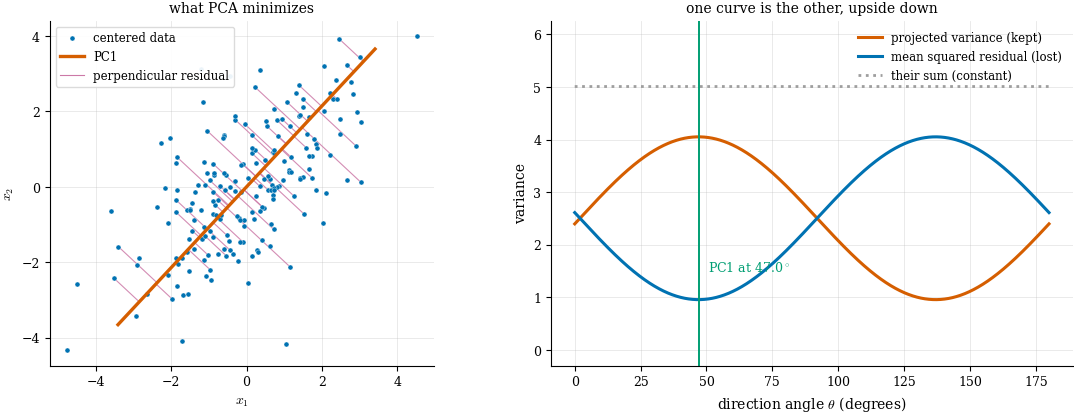

In [4]:
rng_sw = np.random.default_rng(0)
X_sw = rng_sw.normal(size=(200, 2)) @ np.linalg.cholesky(C_pop4).T + np.array([5.0, 3.0])
Xc_sw = X_sw - X_sw.mean(axis=0)
total_sw = (Xc_sw ** 2).sum(axis=1).mean()          # mean squared distance to the mean

theta_sw = np.linspace(0, np.pi, 1801)              # every direction, in 0.1 degree steps
U_sw = np.column_stack([np.cos(theta_sw), np.sin(theta_sw)])
var_sw = np.array([((Xc_sw @ u) ** 2).mean() for u in U_sw])                              # kept
res_sw = np.array([((Xc_sw - np.outer(Xc_sw @ u, u)) ** 2).sum(1).mean() for u in U_sw])  # lost

th_var = theta_sw[int(np.argmax(var_sw))]
th_res = theta_sw[int(np.argmin(res_sw))]
pc1_sw = PCA().fit(X_sw).components_[0]
slope_ols = LinearRegression().fit(X_sw[:, :1], X_sw[:, 1]).coef_[0]

print(f"total spread (mean ||x - mu||^2)      {total_sw:.6f}")
print(f"variance + residual: max - min        {np.ptp(var_sw + res_sw):.2e}   (a constant)")
print(f"angle that MAXIMIZES the variance     {np.degrees(th_var):7.2f} deg")
print(f"angle that MINIMIZES the residual     {np.degrees(th_res):7.2f} deg   identical: {th_var == th_res}")
print(f"angle to sklearn's PC1                {direction_angle_deg(U_sw[np.argmax(var_sw)], pc1_sw):.4f} deg"
      f"   (the sweep's own resolution is 0.1 deg)")
print(f"\nPC1 slope {pc1_sw[1] / pc1_sw[0]:.4f} vs least-squares slope {slope_ols:.4f}"
      f"  -- {direction_angle_deg([1, slope_ols], pc1_sw):.2f} deg apart: PCA is NOT regression")

u_star = U_sw[int(np.argmax(var_sw))]
proj_sw = np.outer(Xc_sw @ u_star, u_star)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 4.2))
ax1.scatter(*Xc_sw.T, s=13, color=C0, edgecolor="white", linewidth=0.25, zorder=3,
            label="centered data")
for a, b in zip(Xc_sw[:60], proj_sw[:60]):
    ax1.plot([a[0], b[0]], [a[1], b[1]], color=CP, lw=0.8, alpha=0.85, zorder=2)
ax1.plot([-5 * u_star[0], 5 * u_star[0]], [-5 * u_star[1], 5 * u_star[1]],
         color=C1, lw=2.4, zorder=4, label="PC1")
ax1.plot([], [], color=CP, lw=0.8, label="perpendicular residual")
ax1.set_aspect("equal"); ax1.set_xlabel("$x_1$"); ax1.set_ylabel("$x_2$")
ax1.legend(fontsize=8.5, loc="upper left", frameon=True, framealpha=0.93,
           facecolor="white", edgecolor="0.85")
ax1.set_title("what PCA minimizes", fontsize=10)

deg_sw = np.degrees(theta_sw)
ax2.plot(deg_sw, var_sw, color=C1, lw=2.2, label="projected variance (kept)")
ax2.plot(deg_sw, res_sw, color=C0, lw=2.2, label="mean squared residual (lost)")
ax2.plot(deg_sw, var_sw + res_sw, ":", color=CX, lw=2.0, label="their sum (constant)")
ax2.axvline(np.degrees(th_var), color=CG, lw=1.4)
ax2.annotate(f"PC1 at {np.degrees(th_var):.1f}$^\\circ$", (np.degrees(th_var), total_sw * 0.30),
             xytext=(7, 0), textcoords="offset points", fontsize=9, color=CG)
ax2.set_xlabel(r"direction angle $\theta$ (degrees)"); ax2.set_ylabel("variance")
ax2.set_ylim(-0.3, total_sw * 1.25)
ax2.legend(fontsize=8.5, loc="upper right", ncols=1)
ax2.set_title("one curve is the other, upside down", fontsize=10)
plt.show()

## 4. How many components, and what it costs to stop there

On the $8\times8$ handwritten digits (1797 images, 64 pixels) we can ask the two practical
questions at once.

**How many?** The **explained-variance ratio** $\lambda_k/\sum_j\lambda_j$ is each component's
share, and the cumulative curve says how many you need to hit a target. Look at the scree plot
before you believe the usual story about elbows: on these raw pixels $90\%$ of the variance needs
**21** of the 64 components and $95\%$ needs **29**. There is no elbow. "A handful of components
carries it" is simply false here, and worth saying out loud, because that sentence appears in a
great many tutorials. (The lecture quotes **31** and **40** &mdash; those are the *standardized*
digits, which is the subject of the next section.)

**What does stopping cost?** Exactly the variance you threw away:

$$\frac1n\sum_i\lVert\mathbf{x}_i-\hat{\mathbf{x}}_i\rVert^2=\sum_{j>k}\lambda_j .$$

That is not an approximation or a bound &mdash; it is an identity. The table checks it by computing
the left side with `inverse_transform` and the right side from the eigenvalues; they agree to
$10^{-13}$, which is round-off. Keeping $k=8$ of 64 components leaves a mean squared error of
$391.7947$ per image and keeps $67.39\%$ of the variance; $k=32$ leaves $40.4247$ and keeps
$96.64\%$. The image strip shows what those numbers look like: recognizable by $k=8$, visually
exact by $k=32$.

digits: 1797 images, 64 pixels each
90% of the variance needs 21 components, 95% needs 29

  k | variance kept | mean ||x - xhat||^2 | sum of discarded eigenvalues | gap
  1 |       14.89% |           1022.5714 |                    1022.5714 | 0.0e+00
  2 |       28.51% |            858.9448 |                     858.9448 | 0.0e+00
  4 |       48.71% |            616.1911 |                     616.1911 | 1.1e-13
  8 |       67.39% |            391.7947 |                     391.7947 | 1.1e-13
 16 |       84.94% |            180.9397 |                     180.9397 | 8.5e-14
 32 |       96.64% |             40.4247 |                      40.4247 | 9.2e-14
 64 |      100.00% |              0.0000 |                       0.0000 | 1.9e-27


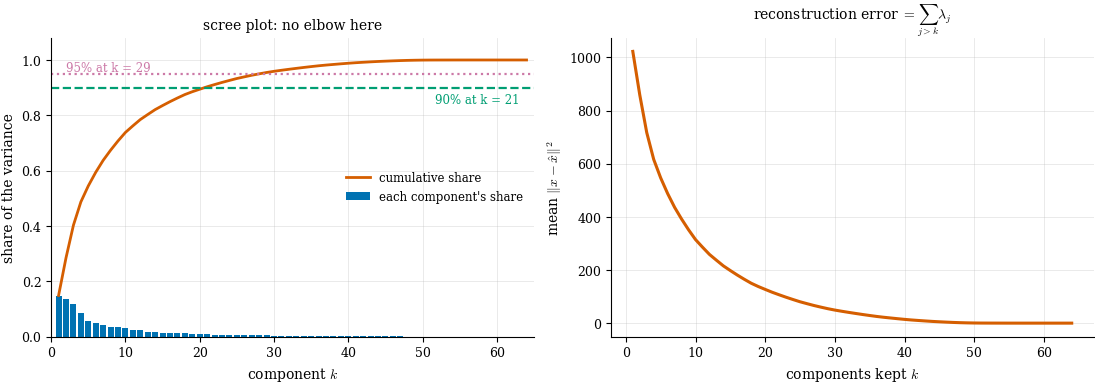

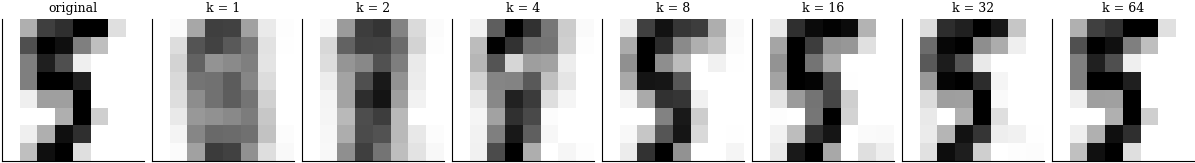

In [5]:
digits = load_digits()
Xd = digits.data
nd = len(Xd)
pca_d = PCA().fit(Xd)
evr_d = pca_d.explained_variance_ratio_
cum_d = np.cumsum(evr_d)
lam_d = pca_d.explained_variance_ * (nd - 1) / nd        # back to the lecture's 1/n convention

print(f"digits: {nd} images, {Xd.shape[1]} pixels each")
print(f"90% of the variance needs {int(np.searchsorted(cum_d, 0.90)) + 1} components, "
      f"95% needs {int(np.searchsorted(cum_d, 0.95)) + 1}")
print("\n  k | variance kept | mean ||x - xhat||^2 | sum of discarded eigenvalues | gap")
fits_d = {}
for k in (1, 2, 4, 8, 16, 32, 64):
    fits_d[k] = PCA(n_components=k).fit(Xd)
    err = ((Xd - fits_d[k].inverse_transform(fits_d[k].transform(Xd))) ** 2).sum(axis=1).mean()
    tail = lam_d[k:].sum()
    print(f" {k:2d} | {100 * cum_d[k - 1]:11.2f}% | {err:19.4f} | {tail:28.4f} | {abs(err - tail):.1e}")

ks_d = np.arange(1, 65)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11.0, 3.9))
a1.bar(ks_d, evr_d, color=C0, label="each component's share")
a1.plot(ks_d, cum_d, color=C1, lw=2.0, label="cumulative share")
# two levels 0.05 apart: give each its own color and put its label beside its own line
for lvl, st, col, xy_lab, ha in ((0.90, "--", CG, (63, 0.845), "right"),
                                 (0.95, ":", CP, (2, 0.958), "left")):
    a1.axhline(lvl, ls=st, color=col, lw=1.6)
    a1.annotate(f"{lvl:.0%} at k = {int(np.searchsorted(cum_d, lvl)) + 1}", xy_lab,
                fontsize=8.5, color=col, ha=ha)
a1.set_xlabel("component $k$"); a1.set_ylabel("share of the variance")
a1.set_xlim(0, 65); a1.set_ylim(0, 1.08); a1.legend(fontsize=8.5, loc="center right")
a1.set_title("scree plot: no elbow here", fontsize=10)
a2.plot(ks_d, [lam_d[k:].sum() for k in ks_d], color=C1, lw=2.2)
a2.set_xlabel("components kept $k$"); a2.set_ylabel(r"mean $\|x-\hat x\|^2$")
a2.set_title(r"reconstruction error $=\sum_{j>k}\lambda_j$", fontsize=10)
plt.show()

img_d = 15                                                   # <-- CHANGE ME
fig, axes = plt.subplots(1, 8, figsize=(12.0, 1.95))
axes[0].imshow(Xd[img_d].reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
axes[0].set_title("original", fontsize=9)
for ax, k in zip(axes[1:], (1, 2, 4, 8, 16, 32, 64)):
    rec = fits_d[k].inverse_transform(fits_d[k].transform(Xd[img_d:img_d + 1]))[0]
    ax.imshow(rec.reshape(8, 8), cmap="gray_r", vmin=0, vmax=16)
    ax.set_title(f"k = {k}", fontsize=9)
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.show()

## 5. PCA has no units &mdash; and that changes the answer

PCA chases *variance*, and variance has units. Multiply a column by 100 and its variance grows by
$10^4$; PCA will hand that column the first component and call it signal. This is not a subtlety
you can shrug off, so here it is measured three times.

**Toy first.** Three hundred people, height and weight, correlation $0.7193$. Recorded in
**meters**, the height column has a standard deviation of $0.101$ against weight's $11.477$, so PC1
is essentially the weight axis (loadings $(0.0063,\,1.0000)$) and keeps $100.00\%$ of the variance
to four decimals &mdash; PCA reports that the data is one-dimensional. Record the *same people*
with height in **centimeters** and PC1 becomes a genuine mix, $(0.6406,\,0.7679)$, keeping
$86.25\%$. Same people, same correlation, different answer. Standardize and the two runs agree to
$0.0000000000^\circ$ &mdash; that is the *point* of standardizing, not a side effect.

**Then real data.** On breast cancer (30 features whose standard deviations span a factor of
$215\,171$) raw PCA puts $98.20\%$ of the variance in PC1, whose largest loading is *worst area*
&mdash; the column that happens to be measured in the biggest numbers. Standardized, PC1 keeps
$44.27\%$ and its largest loading is *mean concave points*, an actual shape measurement.

Does that *matter* downstream? Two principal components, then logistic regression, scored over
5-fold cross-validation repeated 10 times: raw $0.9279\pm0.0188$, standardized $0.9503\pm0.0168$.
Those two intervals overlap, so one split would prove nothing. The **paired** comparison is what
carries the claim &mdash; the same 50 splits scored both ways give a gap of $+0.0223\pm0.0209$, and
standardizing wins on 40 of the 50 splits (4 ties).

**And on the digits**, standardizing moves the $90\%$ point from **21** components to **31** and
the $95\%$ point from **29** to **40** &mdash; the lecture's numbers, reproduced.

> &#128161; **When not to standardize.** When the features already share units and their relative
> sizes are meaningful &mdash; pixels of one image, the same sensor read repeatedly, the time
> samples of a signal. Standardizing digit pixels lifts the near-black border pixels to the same
> importance as the ones in the middle of a stroke, which is exactly why it then takes *more*
> components to reach $90\%$.

correlation between height and weight: 0.7193  (unit-free)

                      sd_1     sd_2   |PC1 loadings|      PC1's share
height in meters     0.101   11.477   [0.0063 1.    ]      1.0000
height in cm        10.071   11.477   [0.6406 0.7679]      0.8625
standardized         1.000    1.000   [0.7071 0.7071]      0.8597

the two standardized answers differ by 0.0000000000 deg



breast cancer: 30 features, sds from 0.00264 to 568.9 (a factor of 215171)
  PC1's share of the variance   raw 98.20%  | standardized 44.27%
  PC1's largest loading         raw 'worst area'  | standardized 'mean concave points'
  accuracy on 2 PCs, 5-fold CV repeated 10 times (50 splits):
     raw            0.9279 +/- 0.0188   (worst 0.8860, best 0.9735)
     standardized   0.9503 +/- 0.0168   (worst 0.9123, best 1.0000)
     paired gap     +0.0223 +/- 0.0209   standardized wins 40 of 50 splits, ties 4

digits: 90% of the variance needs  raw 21 | standardized 31 components
        95% of the variance needs  raw 29 | standardized 40 components


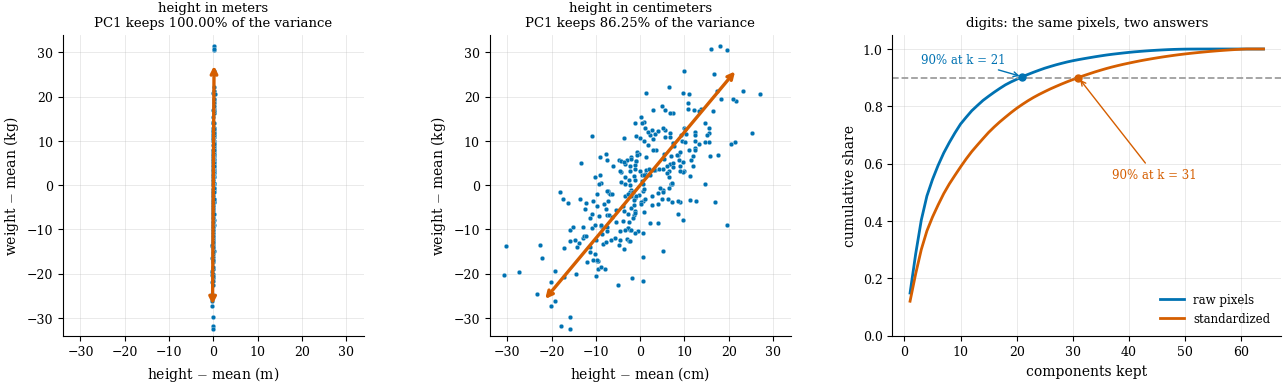

In [6]:
rng_un = np.random.default_rng(4)
h_un = rng_un.normal(1.70, 0.10, 300)                     # height, in meters
w_un = 65 + 80 * (h_un - 1.70) + rng_un.normal(0, 8, 300)  # weight, in kilograms
X_m = np.column_stack([h_un, w_un])
X_cm = np.column_stack([h_un * 100, w_un])                # the SAME people, height in centimeters

print(f"correlation between height and weight: {np.corrcoef(X_m.T)[0, 1]:.4f}  (unit-free)")
print("\n                      sd_1     sd_2   |PC1 loadings|      PC1's share")
for name, Xu in (("height in meters ", X_m), ("height in cm     ", X_cm)):
    p = PCA().fit(Xu)
    print(f"{name} {Xu.std(0)[0]:8.3f} {Xu.std(0)[1]:8.3f}   {np.abs(p.components_[0]).round(4)}"
          f"      {p.explained_variance_ratio_[0]:.4f}")
pm_un = PCA().fit(StandardScaler().fit_transform(X_m))
pcm_un = PCA().fit(StandardScaler().fit_transform(X_cm))
print(f"standardized      {1.0:8.3f} {1.0:8.3f}   {np.abs(pm_un.components_[0]).round(4)}"
      f"      {pm_un.explained_variance_ratio_[0]:.4f}")
print(f"\nthe two standardized answers differ by "
      f"{direction_angle_deg(pm_un.components_[0], pcm_un.components_[0]):.10f} deg")

bc = load_breast_cancer()
sd_bc = bc.data.std(axis=0)
praw_bc = PCA().fit(bc.data)
pstd_bc = PCA().fit(StandardScaler().fit_transform(bc.data))
cv_bc = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0)
s_raw = cross_val_score(make_pipeline(PCA(n_components=2), LogisticRegression(max_iter=5000)),
                        bc.data, bc.target, cv=cv_bc)
s_std = cross_val_score(make_pipeline(StandardScaler(), PCA(n_components=2),
                                      LogisticRegression(max_iter=5000)),
                        bc.data, bc.target, cv=cv_bc)
gap_bc = s_std - s_raw
print(f"\nbreast cancer: 30 features, sds from {sd_bc.min():.5f} to {sd_bc.max():.1f} "
      f"(a factor of {sd_bc.max() / sd_bc.min():.0f})")
print(f"  PC1's share of the variance   raw {100 * praw_bc.explained_variance_ratio_[0]:.2f}%"
      f"  | standardized {100 * pstd_bc.explained_variance_ratio_[0]:.2f}%")
print(f"  PC1's largest loading         raw '{bc.feature_names[np.argmax(np.abs(praw_bc.components_[0]))]}'"
      f"  | standardized '{bc.feature_names[np.argmax(np.abs(pstd_bc.components_[0]))]}'")
print("  accuracy on 2 PCs, 5-fold CV repeated 10 times (50 splits):")
print(f"     raw            {s_raw.mean():.4f} +/- {s_raw.std():.4f}"
      f"   (worst {s_raw.min():.4f}, best {s_raw.max():.4f})")
print(f"     standardized   {s_std.mean():.4f} +/- {s_std.std():.4f}"
      f"   (worst {s_std.min():.4f}, best {s_std.max():.4f})")
print(f"     paired gap     {gap_bc.mean():+.4f} +/- {gap_bc.std():.4f}"
      f"   standardized wins {int((gap_bc > 0).sum())} of {len(gap_bc)} splits, "
      f"ties {int((gap_bc == 0).sum())}")

cum_raw = cum_d
cum_std = np.cumsum(PCA().fit(StandardScaler().fit_transform(Xd)).explained_variance_ratio_)
print(f"\ndigits: 90% of the variance needs  raw {int(np.searchsorted(cum_raw, 0.90)) + 1}"
      f" | standardized {int(np.searchsorted(cum_std, 0.90)) + 1} components")
print(f"        95% of the variance needs  raw {int(np.searchsorted(cum_raw, 0.95)) + 1}"
      f" | standardized {int(np.searchsorted(cum_std, 0.95)) + 1} components")

fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.9))
for ax, (Xu, ttl, xl) in zip(axes, ((X_m, "height in meters", "height $-$ mean (m)"),
                                    (X_cm, "height in centimeters", "height $-$ mean (cm)"))):
    p = PCA().fit(Xu)
    Z = Xu - Xu.mean(axis=0)
    ax.scatter(*Z.T, s=11, color=C0, edgecolor="white", linewidth=0.2, zorder=3)
    v = p.components_[0] * 2.4 * np.sqrt(p.explained_variance_[0])
    ax.annotate("", xy=v, xytext=-v, arrowprops=dict(arrowstyle="<->", color=C1, lw=2.4))
    ax.set_xlim(-34, 34); ax.set_ylim(-34, 34); ax.set_aspect("equal")   # equal: what PCA sees
    ax.set_xlabel(xl); ax.set_ylabel("weight $-$ mean (kg)")
    ax.set_title(f"{ttl}\nPC1 keeps {100 * p.explained_variance_ratio_[0]:.2f}% of the variance",
                 fontsize=9.5)
axes[2].plot(np.arange(1, 65), cum_raw, color=C0, lw=2.0, label="raw pixels")
axes[2].plot(np.arange(1, 65), cum_std, color=C1, lw=2.0, label="standardized")
axes[2].axhline(0.90, ls="--", color=CX, lw=1.3)
for cum_u, col, xy_txt in ((cum_raw, C0, (3.0, 0.95)), (cum_std, C1, (37.0, 0.55))):
    k90 = int(np.searchsorted(cum_u, 0.90)) + 1
    axes[2].plot([k90], [cum_u[k90 - 1]], "o", color=col, ms=5, zorder=4)
    axes[2].annotate(f"90% at k = {k90}", xy=(k90, cum_u[k90 - 1]), xytext=xy_txt,
                     fontsize=8.5, color=col,
                     arrowprops=dict(arrowstyle="->", color=col, lw=1.0))
axes[2].set_xlabel("components kept"); axes[2].set_ylabel("cumulative share")
axes[2].set_ylim(0, 1.05); axes[2].legend(fontsize=8.5, loc="lower right")
axes[2].set_title("digits: the same pixels, two answers", fontsize=9.5)
plt.show()

## 6. The first break: when you have labels, variance is the wrong question

Everything so far ignored the labels, because PCA has no way to use them. Usually that is the
point. But when you *do* have labels and you want the classes **separated**, "where is the
variance?" is a different question &mdash; and PCA can answer it perfectly while destroying
everything you cared about.

The lecture's demonstration, reproduced below: two long parallel clouds. Both classes have the
**same** distribution along $x_1$ and are offset along $x_2$. So $x_1$ is where all the variance
lives and $x_2$ is where all the information lives. **Linear discriminant analysis** asks the
supervised question instead: which direction makes the class means far apart *and* each class
tight? You have met it before &mdash; Session&nbsp;05 used it as a classifier, and Section&nbsp;7
shows the two uses are literally the same vector.

To keep the comparison about the *projection* and not about whatever classifier follows it, we
score each 1-D coordinate with `best_1d_threshold_accuracy`: the best accuracy **any** single
threshold on it could reach.

> &#9888;&#65039; **That statistic's baseline is not $0.5$.** "Best over all thresholds" is a
> maximum over $n-1$ candidate cuts, and a maximum of noise is above the mean of noise. Shuffle
> the labels 2000 times and the same statistic still averages $0.5342\pm0.0106$, with a 95th
> percentile of $0.5550$. PC1's $0.5417$ sits at the **76th percentile of pure noise** &mdash; so
> the honest reading is not "PC1 carries a little signal", it is "PC1 carries none". The null
> depends only on the *ordering* of the scores, so that ceiling applies to any 1-D score on these
> 600 balanced points.

And LDA's $0.9867$ has the mirror-image problem: it is an in-sample optimum of a direction fitted
on all 600 points. Refit on 4/5 of the data, choose the cut on that training part, and score the
held-out fifth &mdash; 5 folds, 10 repeats &mdash; and LDA still gets $0.9810\pm0.0111$ while PCA
falls to $0.5118\pm0.0265$, which is chance with the optimism removed.

the two cigars: 600 points, 300 per class
PC1 keeps 99.24% of the variance, and points 0.09 deg from the x axis
LDA's direction points 0.03 deg from the y axis
the two directions are 89.94 deg apart

IN-SAMPLE, best single threshold   PCA 0.5417   LDA 0.9867


labels shuffled 2000 times          0.5342 +/- 0.0106   (95th percentile 0.5550)
  -> PCA's 0.5417 is the 76th percentile of NOISE: no class information at all
the cut helper reproduces nb_data's in-sample number: True

HELD OUT (5 folds x 10 repeats; direction and cut fitted on the training part)
  PCA  0.5118 +/- 0.0265
  LDA  0.9810 +/- 0.0111


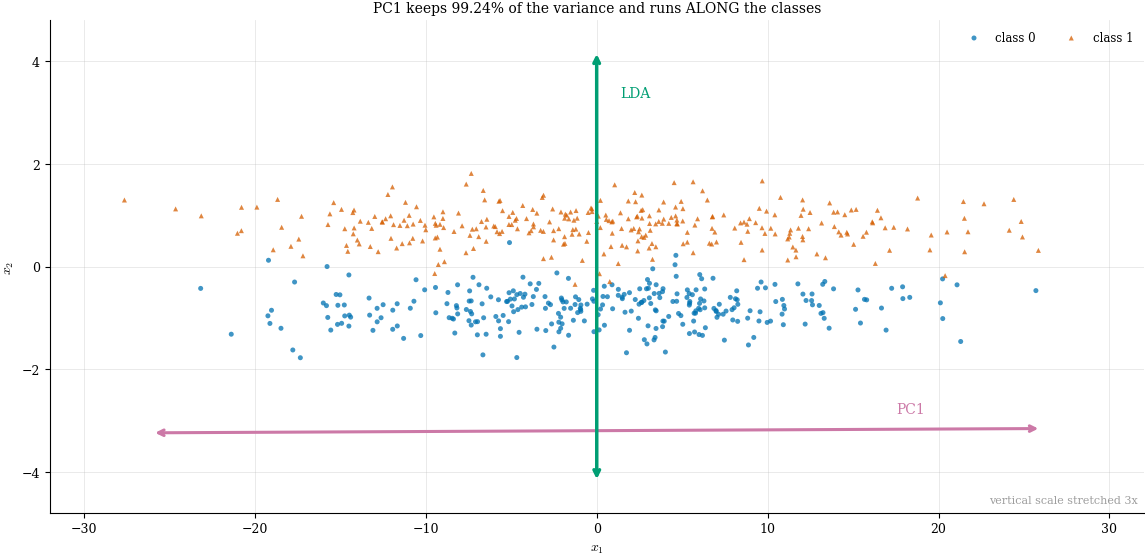

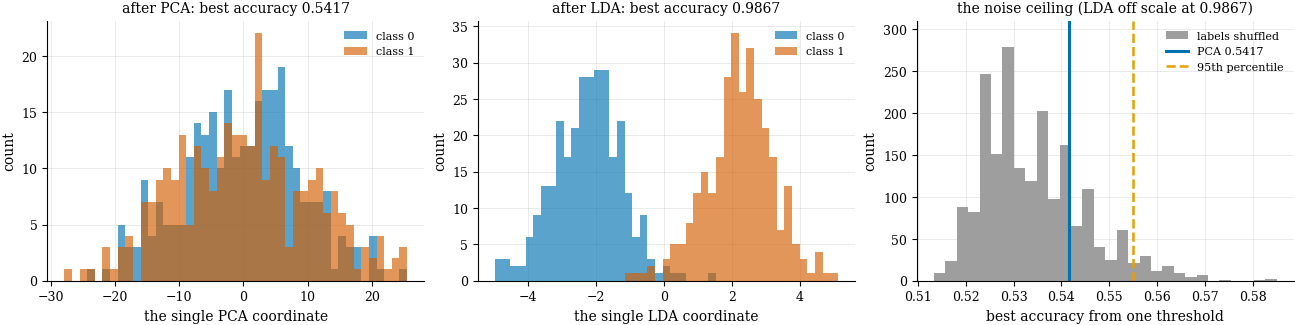

In [7]:
Xcg, ycg = make_cigars()                         # 300 points per class; n is PER CLASS
pca_cg = PCA().fit(Xcg)
lda_cg = LDA(n_components=1).fit(Xcg, ycg)
z_pca_cg = PCA(n_components=1).fit_transform(Xcg)
z_lda_cg = lda_cg.transform(Xcg)
acc_pca_cg = best_1d_threshold_accuracy(z_pca_cg, ycg)
acc_lda_cg = best_1d_threshold_accuracy(z_lda_cg, ycg)

print(f"the two cigars: {len(Xcg)} points, {int((ycg == 0).sum())} per class")
print(f"PC1 keeps {100 * pca_cg.explained_variance_ratio_[0]:.2f}% of the variance, and points"
      f" {direction_angle_deg(pca_cg.components_[0], [1, 0]):.2f} deg from the x axis")
print(f"LDA's direction points {direction_angle_deg(lda_cg.coef_[0], [0, 1]):.2f} deg from the y axis")
print(f"the two directions are {direction_angle_deg(pca_cg.components_[0], lda_cg.coef_[0]):.2f} deg apart")
print(f"\nIN-SAMPLE, best single threshold   PCA {acc_pca_cg:.4f}   LDA {acc_lda_cg:.4f}")

# the baseline: the SAME statistic on shuffled labels -- what pure noise scores
rng_nz = np.random.default_rng(0)
null_cg = np.array([best_1d_threshold_accuracy(z_pca_cg, rng_nz.permutation(ycg))
                    for _ in range(2000)])
print(f"labels shuffled 2000 times          {null_cg.mean():.4f} +/- {null_cg.std():.4f}"
      f"   (95th percentile {np.quantile(null_cg, 0.95):.4f})")
print(f"  -> PCA's {acc_pca_cg:.4f} is the {100 * (null_cg < acc_pca_cg).mean():.0f}th percentile "
      f"of NOISE: no class information at all")


def best_cut_cg(z, y):
    "the threshold, and which side is class 1, that maximize accuracy on (z, y)"
    z = np.asarray(z, float).ravel()
    y = np.asarray(y).ravel()
    o = np.argsort(z)
    zs, ys = z[o], y[o]
    n = len(ys)
    ones = np.cumsum(ys == 1)
    i = np.arange(n - 1)
    hi = ((i + 1 - ones[:-1]) + (ones[-1] - ones[:-1])) / n     # predict class 1 ABOVE the cut
    acc = np.where(hi >= 0.5, hi, 1 - hi)
    j = int(np.argmax(acc))
    return 0.5 * (zs[j] + zs[j + 1]), (1 if hi[j] >= 0.5 else -1), float(acc[j])


print(f"the cut helper reproduces nb_data's in-sample number: "
      f"{abs(best_cut_cg(z_pca_cg, ycg)[2] - acc_pca_cg) < 1e-12}")

hold_cg = {"PCA": [], "LDA": []}
for rep in range(10):
    for tr, te in StratifiedKFold(5, shuffle=True, random_state=rep).split(Xcg, ycg):
        for nm, m in (("PCA", PCA(n_components=1).fit(Xcg[tr])),
                      ("LDA", LDA(n_components=1).fit(Xcg[tr], ycg[tr]))):
            thr, sgn, _ = best_cut_cg(m.transform(Xcg[tr]), ycg[tr])      # cut from TRAIN only
            zte = m.transform(Xcg[te]).ravel()
            pred = (zte > thr).astype(int) if sgn == 1 else (zte <= thr).astype(int)
            hold_cg[nm].append((pred == ycg[te]).mean())
print("\nHELD OUT (5 folds x 10 repeats; direction and cut fitted on the training part)")
for nm in ("PCA", "LDA"):
    a = np.array(hold_cg[nm])
    print(f"  {nm}  {a.mean():.4f} +/- {a.std():.4f}")

vstretch_cg = 3.0                  # y is STRETCHED, or 600 points collapse into one flat band
fig, ax = plt.subplots(figsize=(11.5, 5.9))
for cls, col, mk in ((0, C0, "o"), (1, C1, "^")):
    ax.scatter(*Xcg[ycg == cls].T, s=13, marker=mk, color=col, alpha=0.75,
               edgecolor="none", label=f"class {cls}")
pc_cg, wl_cg = pca_cg.components_[0], unit(lda_cg.coef_[0])
off_cg = np.array([0.0, -3.2])     # PC1 drawn BELOW the seam, so it hides no points
ax.annotate("", xy=pc_cg * 26 + off_cg, xytext=-pc_cg * 26 + off_cg,
            arrowprops=dict(arrowstyle="<->", color=CP, lw=2.2))
ax.annotate("PC1", xy=(17.5, off_cg[1] + 0.35), color=CP, fontsize=10)
ax.annotate("", xy=wl_cg * 4.2, xytext=-wl_cg * 4.2,
            arrowprops=dict(arrowstyle="<->", color=CG, lw=2.5))
ax.annotate("LDA", xy=(1.4, 3.3), color=CG, fontsize=10)
ax.set_xlim(-32, 32); ax.set_ylim(-4.8, 4.8); ax.set_aspect(vstretch_cg)
ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$")
ax.text(0.995, 0.015, f"vertical scale stretched {vstretch_cg:g}x", transform=ax.transAxes,
        ha="right", va="bottom", fontsize=8, color=CX)
ax.legend(fontsize=8.5, loc="upper right", ncols=2)
ax.set_title(f"PC1 keeps {100 * pca_cg.explained_variance_ratio_[0]:.2f}% of the variance "
             f"and runs ALONG the classes", fontsize=10)
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(13.0, 3.3))
for axh, (z, name, acc) in zip(axs, ((z_pca_cg, "PCA", acc_pca_cg),
                                     (z_lda_cg, "LDA", acc_lda_cg))):
    bins = np.linspace(z.min(), z.max(), 46)
    for cls, c in ((0, C0), (1, C1)):
        axh.hist(z.ravel()[ycg == cls], bins=bins, alpha=0.65, color=c, label=f"class {cls}")
    axh.set_xlabel(f"the single {name} coordinate"); axh.set_ylabel("count")
    axh.legend(fontsize=8, loc="upper right")
    axh.set_title(f"after {name}: best accuracy {acc:.4f}", fontsize=10)
axs[2].hist(null_cg, bins=30, color=CX, label="labels shuffled")
axs[2].axvline(acc_pca_cg, color=C0, lw=2.2, label=f"PCA {acc_pca_cg:.4f}")
axs[2].axvline(np.quantile(null_cg, 0.95), color=CN, ls="--", lw=1.8, label="95th percentile")
axs[2].set_xlabel("best accuracy from one threshold"); axs[2].set_ylabel("count")
axs[2].set_ylim(0, 310); axs[2].legend(fontsize=8, loc="upper right")
axs[2].set_title(f"the noise ceiling (LDA off scale at {acc_lda_cg:.4f})", fontsize=10)
plt.show()

## 7. LDA in three lines of algebra &mdash; and its two walls

Split the spread into the part *within* each class and the part *between* the classes,

$$S_W=\sum_k\sum_{i:\,y_i=k}(\mathbf{x}_i-\boldsymbol\mu_k)(\mathbf{x}_i-\boldsymbol\mu_k)^\top,
\qquad S_B=\sum_k n_k(\boldsymbol\mu_k-\boldsymbol\mu)(\boldsymbol\mu_k-\boldsymbol\mu)^\top,$$

and maximize the ratio $J(\mathbf{w})=\mathbf{w}^\top S_B\mathbf{w}/\mathbf{w}^\top S_W\mathbf{w}$.
For **two** classes no eigensolver is needed, because $S_B$ has rank 1 and every vector it produces
points along $\boldsymbol\mu_1-\boldsymbol\mu_0$:

$$\mathbf{w}\;\propto\;S_W^{-1}(\boldsymbol\mu_1-\boldsymbol\mu_0).$$

The lecture's eight integer points make $S_W$ exactly $8I$, so $S_W^{-1}=0.125\,I$ and
$\mathbf{w}=0.125\cdot(4,4)=(0.5,0.5)$ &mdash; done on paper. Then the same two lines run on the
cigars, where **four different routes** (the closed form, Session&nbsp;05's
$\Sigma^{-1}(\boldsymbol\mu_1-\boldsymbol\mu_0)$, the top generalized eigenvector of
$S_B\mathbf{w}=\lambda S_W\mathbf{w}$, and scikit-learn's `coef_`) return one and the same
direction: $1-|\cos|=1.1\times10^{-16}$, one unit in the last place of a double.

> &#9888;&#65039; **Why we print $1-|\cos|$ and not just the angle.** The slide quotes
> $0.0000000000^\circ$; this run prints $0.0000008538^\circ$ (those last digits are round-off and
> may come out differently on your machine), and *both are the same claim*.
> $\arccos$ is flat near $1$: an error of $10^{-16}$ in the cosine comes out as $\sim10^{-6}$
> degrees in the angle. So an angle of $10^{-6}$ degrees is not disagreement, it is arithmetic.
> Test exact collinearity with $1-|\cos\theta|<10^{-12}$, never with a tight angular threshold.

Two walls follow from the same matrix $S_B$:

* **At most $K-1$ directions.** $S_B$ is built from $K$ means measured about *their own* average,
  so one degree of freedom is already spent and its rank is $K-1$. Two classes give you exactly
  **one** direction no matter how many features you started with &mdash; verified below against
  `LDA.transform` for $K=2,\dots,6$ on 8-dimensional data.
* **Blind to shape.** Give two classes the *same* mean and different covariances and $S_B$ nearly
  vanishes ($\lVert S_B\rVert=2.32$ on 800 points), so there is nothing to maximize: the best
  threshold on LDA's direction reaches $0.5675$ *in sample* on data that is obviously separable.
  Session&nbsp;05 met this exact wall and stepped over it by letting each class keep its own
  covariance &mdash; **QDA** scores $0.8974\pm0.0207$ here, held out over 50 splits.

In [8]:
def scatter_matrices(X, y):
    "within-class and between-class scatter: S_W, S_B"
    X = np.asarray(X, float)
    mu = X.mean(axis=0)
    SW = np.zeros((X.shape[1], X.shape[1]))
    SB = np.zeros_like(SW)
    for k in np.unique(y):
        Xk = X[y == k]
        muk = Xk.mean(axis=0)
        SW += (Xk - muk).T @ (Xk - muk)
        SB += len(Xk) * np.outer(muk - mu, muk - mu)
    return SW, SB


X8 = np.array([[2, 2], [2, 4], [4, 2], [4, 4], [6, 6], [6, 8], [8, 6], [8, 8]], float)
y8 = np.array([0, 0, 0, 0, 1, 1, 1, 1])
SW8, SB8 = scatter_matrices(X8, y8)
d8 = X8[y8 == 1].mean(0) - X8[y8 == 0].mean(0)
w8 = np.linalg.solve(SW8, d8)
sk8 = LDA(solver="eigen").fit(X8, y8)
print(f"mu_1 - mu_0 = {d8}")
print(f"S_W         = {SW8.tolist()}   ->  S_W^-1 = {np.linalg.inv(SW8).tolist()}")
print(f"S_B         = {SB8.tolist()}   rank {np.linalg.matrix_rank(SB8)}")
print(f"w = S_W^-1 (mu_1 - mu_0) = {w8}, i.e. the direction {unit(w8).round(6)}")
print(f"sklearn's coef_ = {sk8.coef_[0]}, {direction_angle_deg(sk8.coef_[0], w8):.1e} deg away")

SWg, SBg = scatter_matrices(Xcg, ycg)
dg = Xcg[ycg == 1].mean(0) - Xcg[ycg == 0].mean(0)
w_scratch = np.linalg.solve(SWg, dg)
w_s05 = np.linalg.solve(SWg / len(Xcg), dg)            # session 05: Sigma^-1 (mu_1 - mu_0)
evals_g, evecs_g = eigh(SBg, SWg)                      # S_B w = lambda S_W w
w_gen = evecs_g[:, np.argmax(evals_g)]
print("\non the cigars, four routes to one direction:")
for nm, v in (("S_W^-1 (mu_1 - mu_0)", w_scratch),
              ("session 05's Sigma^-1 (mu1 - mu0)", w_s05),
              ("top eigenvector of S_B w = l S_W w", w_gen),
              ("sklearn's LDA.coef_", lda_cg.coef_[0])):
    print(f"  {nm:36s} {unit(v).round(8)}   1 - |cos| to the first: "
          f"{1 - abs(unit(v) @ unit(w_scratch)):.1e}")
print(f"  the angle between the first two: {direction_angle_deg(w_scratch, w_s05):.10f} deg"
      f"  <- arccos noise, not disagreement")

print("\n K | rank(S_B) | columns of LDA.transform(X), on 8 features")
rng_K = np.random.default_rng(0)
for K in (2, 3, 4, 5, 6):
    Xs = np.vstack([rng_K.normal(size=(60, 8)) + 4 * np.eye(8)[k] for k in range(K)])
    ys = np.repeat(np.arange(K), 60)
    cols = LDA().fit(Xs, ys).transform(Xs).shape[1]
    print(f" {K} | {np.linalg.matrix_rank(scatter_matrices(Xs, ys)[1], tol=1e-8):9d} | {cols}")

rng_sh = np.random.default_rng(3)
Xsh = np.vstack([rng_sh.normal(size=(400, 2)) * [3.0, 0.4],
                 rng_sh.normal(size=(400, 2)) * [0.4, 3.0]])
ysh = np.array([0] * 400 + [1] * 400)
acc_blind = best_1d_threshold_accuracy(LDA(n_components=1).fit(Xsh, ysh).transform(Xsh), ysh)
qda_sh = cross_val_score(QDA(), Xsh, ysh,
                         cv=RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=0))
print(f"\ntwo classes, SAME mean and different shapes ({len(Xsh)} points): ||S_B|| = "
      f"{np.linalg.norm(scatter_matrices(Xsh, ysh)[1]):.2f}")
print(f"  best IN-SAMPLE 1-D accuracy after LDA  {acc_blind:.4f}")
print(f"  session 05's QDA, 5-fold x 10 repeats  {qda_sh.mean():.4f} +/- {qda_sh.std():.4f}")

mu_1 - mu_0 = [4. 4.]
S_W         = [[8.0, 0.0], [0.0, 8.0]]   ->  S_W^-1 = [[0.125, 0.0], [0.0, 0.125]]
S_B         = [[32.0, 32.0], [32.0, 32.0]]   rank 1
w = S_W^-1 (mu_1 - mu_0) = [0.5 0.5], i.e. the direction [0.707107 0.707107]
sklearn's coef_ = [4. 4.], 0.0e+00 deg away

on the cigars, four routes to one direction:
  S_W^-1 (mu_1 - mu_0)                 [-5.5580000e-04  9.9999985e-01]   1 - |cos| to the first: 1.1e-16
  session 05's Sigma^-1 (mu1 - mu0)    [-5.5580000e-04  9.9999985e-01]   1 - |cos| to the first: 1.1e-16
  top eigenvector of S_B w = l S_W w   [-5.5580000e-04  9.9999985e-01]   1 - |cos| to the first: 1.1e-16
  sklearn's LDA.coef_                  [-5.5580000e-04  9.9999985e-01]   1 - |cos| to the first: 1.1e-16
  the angle between the first two: 0.0000008538 deg  <- arccos noise, not disagreement

 K | rank(S_B) | columns of LDA.transform(X), on 8 features
 2 |         1 | 1
 3 |         2 | 2
 4 |         3 | 3
 5 |         4 | 4
 6 |         5 | 5

two classes,

## 8. The second break: when the noise is per feature

PCA asks a geometric question. **Factor analysis** asks a generative one &mdash; what small set of
hidden causes would produce data like this? &mdash; and writes the answer down as a model:

$$\mathbf{x}=W\mathbf{z}+\boldsymbol\mu+\boldsymbol\varepsilon,\qquad
\mathbf{z}\sim\mathcal N(\mathbf 0,I),\qquad
\boldsymbol\varepsilon\sim\mathcal N(\mathbf 0,\Psi),\ \ \Psi\ \textbf{diagonal},$$

which implies $\mathrm{Cov}(\mathbf{x})=WW^\top+\Psi$: a low-rank part the shared factors explain,
plus a variance **private to each feature**. That diagonal is the entire difference from PCA, and
here is what it buys.

Five features are driven by one hidden factor with loadings $(1.0,0.9,0.8,0.7,0.6)$. Then feature 5
is multiplied by ten &mdash; the *same information*, recorded on a noisier instrument. Rescale the
fitted direction back into the original units and ask how far it moved. One draw of that experiment
would prove nothing, so the cell runs **20** independent draws:

| over 20 draws | mean | range |
|---|---|---|
| PCA's direction moved | $6.993^\circ$ | $5.561^\circ$ to $8.024^\circ$ |
| factor analysis's direction moved | $0.0024^\circ$ | $0.0004^\circ$ to $0.0052^\circ$ |

PCA moves further on **20 of 20** draws, and the ratio of the two means is **$2867\times$**. That
ratio is quotable, because factor analysis's movement here is *resolved*, not lost in noise: it is
strictly positive on all 20 draws, and even the smallest of them, $0.0004^\circ$, is $363\times$ the
$\sim10^{-6}$-degree floor that $\arccos$ imposes on an angle this small (&sect;7). Compare that with
what round-off actually looks like in this notebook &mdash; in &sect;5 two runs that must agree came
out $0.0000000000^\circ$ apart. So $0.0024^\circ$ is tiny but real, and repeatably positive.

There *is* a caution to make here, and it is a different one: that floor is set by where
`FactorAnalysis` stops iterating &mdash; EM's `tol=0.01` on the log-likelihood, with the default
randomized SVD pinned by `random_state=0` &mdash; not by floating-point round-off. Tighten the
tolerance, or change scikit-learn version, and the digits after the third will move. What will not
move is the conclusion: PCA swings by *degrees* and factor analysis by *thousandths* of a degree,
on every one of the 20 draws.

The mechanism is the evidence. PCA maximizes variance, feature 5 now has a hundred times more of
it, and PCA has no vocabulary for *"that one is just noisier"*. $\Psi$ **is** that vocabulary: on
the first draw the feature variances after the rescale are $[1.17,\,0.99,\,0.85,\,0.64,\,51.08]$
while the fitted noise variances are $[0.18,\,0.16,\,0.15,\,0.15,\,15.56]$ &mdash; feature 5's extra
variance has been quarantined in its private noise instead of dragging the shared factor toward it.

**Reconciling with the lecture.** The slide for this experiment quotes single numbers,
$8.280^\circ$ against $0.003^\circ$, because `code/l11_data.py` pins one draw with `FA_SEED = 7`.
The cell re-runs precisely that draw and reproduces both &mdash; and that draw is *larger than all
20* of ours (our largest PCA swing is $8.024^\circ$; the same is true of its FA-vs-PCA agreement on
the original data, $0.258^\circ$ against our largest $0.233^\circ$). That is simply what a fixed
seed is: one sample from the range in the table, which here happens to sit at the top of it. Neither
number is wrong. What reproduces across seeds is the *mechanism* and the order of magnitude, so the
range is the honest form of the slide's claim &mdash; read the slide as one worked instance of it.

> &#128161; **The honest reading of "standardize before PCA".** Standardizing is a crude, by-hand
> version of what $\Psi$ does by fitting: it forces every feature to the same variance whether or
> not that is true. On the *original* data, where the noise really is the same in every feature,
> factor analysis and PCA agree to $0.148^\circ$ on average &mdash; the model only earns its keep
> when the per-feature noise genuinely differs.

how far the fitted direction moves when feature 5 is recorded x10, 20 draws:
  PCA               mean 6.993 deg    (range 5.561 to 8.024)
  factor analysis   mean 0.0024 deg   (range 0.0004 to 0.0052)
  PCA moved further on 20 of 20 draws
  every FA angle is strictly POSITIVE, on 20 of 20; the smallest, 0.0004 deg, is 363x the ~1e-6 deg floor arccos imposes (section 7)   <- small, but resolved
  ratio of the means: PCA swings 2867x further
  (FA's EM stops at tol=0.01 on the log-likelihood, so 0.0024 deg is a convergence floor -- not float round-off)

on the ORIGINAL data the two agree to 0.148 deg on average  (range 0.063 to 0.233)

the lecture's single draw (l11_data.py: FA_SEED = 7), identical recipe:
  PCA moved 8.280 deg, factor analysis 0.003 deg   <- the slide's two numbers, reproduced
  it is larger than 20 of the 20 draws above (our largest 8.024); so is its agreement on the original data, 0.258 vs our largest 0.233

the first draw in detail:
  feature variances after the resc

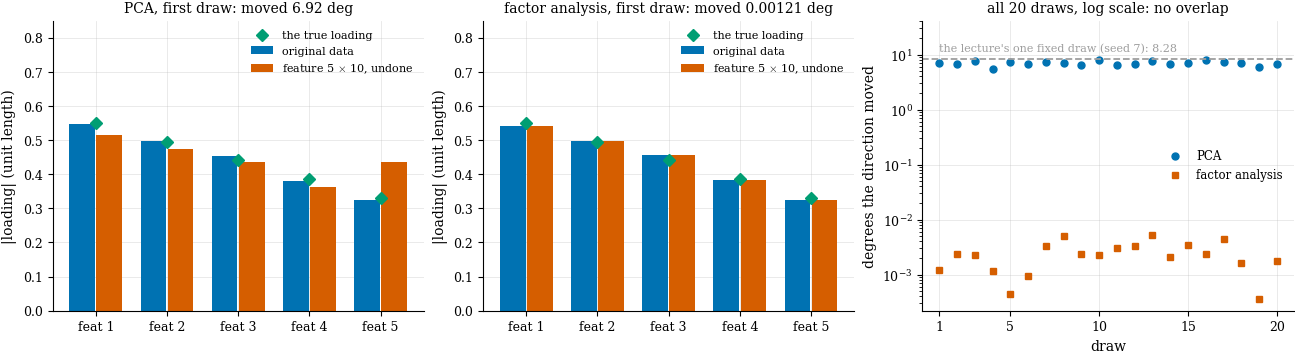

In [9]:
loading_fa = np.array([1.0, 0.9, 0.8, 0.7, 0.6])     # one hidden factor drives five features
rescale_fa = 10.0                                    # <-- CHANGE ME (feature 5's noisier instrument)
undo_fa = np.array([1.0, 1.0, 1.0, 1.0, 1.0 / rescale_fa])   # back into the original units

mv_pca, mv_fa, agree_fa = [], [], []
first = {}
for s in range(20):
    rng_fa = np.random.default_rng(100 + s)
    zf = rng_fa.normal(size=(600, 1))
    Xf = zf @ loading_fa.reshape(1, -1) + rng_fa.normal(size=(600, 5)) * 0.4
    Xr = Xf.copy()
    Xr[:, 4] *= rescale_fa
    pc_before = PCA(n_components=1).fit(Xf).components_[0]
    pc_after = PCA(n_components=1).fit(Xr).components_[0]
    fa_before = FactorAnalysis(n_components=1, random_state=0).fit(Xf)
    fa_after = FactorAnalysis(n_components=1, random_state=0).fit(Xr)
    mv_pca.append(direction_angle_deg(pc_before, pc_after * undo_fa))
    mv_fa.append(direction_angle_deg(fa_before.components_[0], fa_after.components_[0] * undo_fa))
    agree_fa.append(direction_angle_deg(fa_before.components_[0], pc_before))
    if s == 0:
        first = dict(var=Xr.var(axis=0), psi=fa_after.noise_variance_,
                     pb=pc_before, pa=pc_after * undo_fa,
                     fb=fa_before.components_[0], fa=fa_after.components_[0] * undo_fa)
mv_pca, mv_fa, agree_fa = np.array(mv_pca), np.array(mv_fa), np.array(agree_fa)

print(f"how far the fitted direction moves when feature 5 is recorded x{rescale_fa:g}, 20 draws:")
print(f"  PCA               mean {mv_pca.mean():.3f} deg    (range {mv_pca.min():.3f} to {mv_pca.max():.3f})")
print(f"  factor analysis   mean {mv_fa.mean():.4f} deg   (range {mv_fa.min():.4f} to {mv_fa.max():.4f})")
print(f"  PCA moved further on {int((mv_pca > mv_fa).sum())} of 20 draws")
print(f"  every FA angle is strictly POSITIVE, on {int((mv_fa > 0).sum())} of 20; the smallest,"
      f" {mv_fa.min():.4f} deg, is {mv_fa.min() / 1e-6:.0f}x the ~1e-6 deg floor arccos imposes"
      f" (section 7)   <- small, but resolved")
print(f"  ratio of the means: PCA swings {mv_pca.mean() / mv_fa.mean():.0f}x further")
print(f"  (FA's EM stops at tol={FactorAnalysis().tol} on the log-likelihood, so "
      f"{mv_fa.mean():.4f} deg is a convergence floor -- not float round-off)")
print(f"\non the ORIGINAL data the two agree to {agree_fa.mean():.3f} deg on average"
      f"  (range {agree_fa.min():.3f} to {agree_fa.max():.3f})")
# the lecture works ONE fixed draw: code/l11_data.py sets FA_SEED = 7. Re-run exactly it.
rng_lec = np.random.default_rng(7)
z_lec = rng_lec.normal(size=(600, 1))
X_lec = z_lec @ loading_fa.reshape(1, -1) + rng_lec.normal(size=(600, 5)) * 0.4
Xr_lec = X_lec.copy()
Xr_lec[:, 4] *= rescale_fa
pc_lec = PCA(n_components=1).fit(X_lec).components_[0]
pc_lec_r = PCA(n_components=1).fit(Xr_lec).components_[0]
fa_lec = FactorAnalysis(n_components=1, random_state=0).fit(X_lec).components_[0]
fa_lec_r = FactorAnalysis(n_components=1, random_state=0).fit(Xr_lec).components_[0]
rot_pca_lec = direction_angle_deg(pc_lec, pc_lec_r * undo_fa)
rot_fa_lec = direction_angle_deg(fa_lec, fa_lec_r * undo_fa)
agree_lec = direction_angle_deg(fa_lec, pc_lec)
print(f"\nthe lecture's single draw (l11_data.py: FA_SEED = 7), identical recipe:")
print(f"  PCA moved {rot_pca_lec:.3f} deg, factor analysis {rot_fa_lec:.3f} deg"
      f"   <- the slide's two numbers, reproduced")
print(f"  it is larger than {int((mv_pca < rot_pca_lec).sum())} of the 20 draws above "
      f"(our largest {mv_pca.max():.3f}); so is its agreement on the original data, "
      f"{agree_lec:.3f} vs our largest {agree_fa.max():.3f}")

print(f"\nthe first draw in detail:")
print(f"  feature variances after the rescale  {first['var'].round(2)}")
print(f"  factor analysis's private noise Psi  {first['psi'].round(2)}"
      f"   <- feature 5's extra variance, quarantined")

fig, axes = plt.subplots(1, 3, figsize=(13.0, 3.6))
idx = np.arange(5)
for ax, (nm, b, a, mv) in zip(axes, (("PCA", first["pb"], first["pa"], mv_pca[0]),
                                     ("factor analysis", first["fb"], first["fa"], mv_fa[0]))):
    ax.bar(idx - 0.19, np.abs(unit(b)), 0.36, color=C0, label="original data")
    ax.bar(idx + 0.19, np.abs(unit(a)), 0.36, color=C1, label=r"feature 5 $\times$ 10, undone")
    ax.plot(idx, unit(loading_fa), "D", color=CG, ms=6, label="the true loading")
    ax.set_xticks(idx, [f"feat {i + 1}" for i in idx])
    ax.set_ylim(0, 0.85); ax.set_ylabel("|loading| (unit length)")
    ax.legend(fontsize=8.0, loc="upper right")
    ax.set_title(f"{nm}, first draw: moved {mv:.3g} deg", fontsize=10)
axes[2].semilogy(np.arange(1, 21), mv_pca, "o", color=C0, ms=5, label="PCA")
axes[2].semilogy(np.arange(1, 21), mv_fa, "s", color=C1, ms=5, label="factor analysis")
axes[2].set_xlabel("draw"); axes[2].set_ylabel("degrees the direction moved")
axes[2].set_xticks([1, 5, 10, 15, 20]); axes[2].legend(fontsize=8.5, loc="center right")
axes[2].axhline(rot_pca_lec, color=CX, ls="--", lw=1.3)
axes[2].set_ylim(top=rot_pca_lec * 5.0)                   # room for the label above the line
axes[2].annotate(f"the lecture's one fixed draw (seed 7): {rot_pca_lec:.2f}",
                 (1.0, rot_pca_lec * 1.35), fontsize=8.0, color=CX, ha="left")
axes[2].set_title("all 20 draws, log scale: no overlap", fontsize=10)
plt.show()

## 9. And what that model costs: the factors are not identified

For **any** orthogonal $R$,

$$(WR)(WR)^\top+\Psi = WRR^\top W^\top+\Psi = WW^\top+\Psi ,$$

so $W$ and $WR$ predict *exactly* the same covariance. Factor analysis cannot tell them apart, and
neither can any amount of data. Below: six features driven by two hidden factors, in two clean
blocks. The fitted $W$ has the "simple structure" you would hope for &mdash; factor 1 loads on
features 4&ndash;6, factor 2 on features 1&ndash;3, so you could *name* them. Rotate by $37^\circ$
and every feature loads on both factors, the loadings move by up to $0.6429$, factor 1 turns
$34.2^\circ$ &mdash; and the implied covariance changes by $2.2\times10^{-16}$. Nothing was fitted
better or worse.

The *subspace* the two factors span is identical either way (both principal cosines are $1$), and
that is the part factor analysis really determines. Which basis of that subspace you report is a
choice, which is why the field comes with rotation methods (varimax and friends): they pick, out of
a continuum of equally good answers, one that is easy to name.

> &#9888;&#65039; **So if someone names a factor, they chose that name from a continuum.** PCA does
> not have this freedom: its components are orthogonal *and* ordered by variance ($2.859$ then
> $2.344$ here), so "the first principal component" means something.

In [10]:
rng_rot = np.random.default_rng(12)
z_rot = rng_rot.normal(size=(800, 2))
A_true = np.array([[1.0, 0.9, 0.8, 0.0, 0.0, 0.0],      # factor A drives features 1-3
                   [0.0, 0.0, 0.0, 1.0, 0.9, 0.8]])     # factor B drives features 4-6
X_rot = z_rot @ A_true + rng_rot.normal(size=(800, 6)) * 0.4
fa_rot = FactorAnalysis(n_components=2, random_state=0).fit(X_rot)
W_rot = fa_rot.components_.T
Psi_rot = np.diag(fa_rot.noise_variance_)
th_rot = math.radians(37.0)                                        # <-- CHANGE ME
R_rot = np.array([[math.cos(th_rot), -math.sin(th_rot)],
                  [math.sin(th_rot), math.cos(th_rot)]])
WR_rot = W_rot @ R_rot

print("              fitted W           rotated W R")
print("            f1      f2         f1      f2")
for i in range(6):
    print(f"  feature {i + 1}  {W_rot[i, 0]:6.3f} {W_rot[i, 1]:6.3f}     "
          f"{WR_rot[i, 0]:6.3f} {WR_rot[i, 1]:6.3f}")
print(f"\nR is orthogonal: max |R'R - I| = {np.abs(R_rot.T @ R_rot - np.eye(2)).max():.1e}")
print(f"max |(W W' + Psi) - ((WR)(WR)' + Psi)| = {np.abs(W_rot @ W_rot.T - WR_rot @ WR_rot.T).max():.1e}")
print(f"but the loadings themselves differ by up to {np.abs(W_rot - WR_rot).max():.4f}")
print(f"factor 1 turned {direction_angle_deg(W_rot[:, 0], WR_rot[:, 0]):.1f} deg, yet the SUBSPACE "
      f"is unchanged (principal cosines "
      f"{np.linalg.svd(np.linalg.qr(W_rot)[0].T @ np.linalg.qr(WR_rot)[0], compute_uv=False).round(10)})")
print("\nPCA, where this does not happen -- components orthogonal AND ordered, variances",
      PCA(n_components=2).fit(X_rot).explained_variance_.round(3))

              fitted W           rotated W R
            f1      f2         f1      f2
  feature 1  -0.140  0.931      0.448  0.828
  feature 2  -0.121  0.864      0.423  0.763
  feature 3  -0.077  0.735      0.381  0.633
  feature 4   1.033  0.106      0.889 -0.536
  feature 5   0.928  0.096      0.799 -0.482
  feature 6   0.857  0.089      0.738 -0.445

R is orthogonal: max |R'R - I| = 1.9e-17
max |(W W' + Psi) - ((WR)(WR)' + Psi)| = 2.2e-16
but the loadings themselves differ by up to 0.6429
factor 1 turned 34.2 deg, yet the SUBSPACE is unchanged (principal cosines [1. 1.])

PCA, where this does not happen -- components orthogonal AND ordered, variances [2.859 2.344]


## 10. The third break: when a negative amount makes no sense

Pixel intensities, word counts, spectra, play counts &mdash; all non-negative, and "minus three of
them" means nothing. PCA does not care: it will hand you components with negative entries and
reconstruct a digit by *subtracting* one pattern from another. **NMF** refuses:

$$X\approx WH,\qquad X,\,W,\,H\ \geq\ 0 .$$

Nothing can cancel, so every image must be built by **adding up parts**. The constraint is the
whole method, and its consequences are measurable on the same digits, with $k=10$ components each:

| on the digits, $k=10$ | PCA | NMF |
|---|---|---|
| share of basis entries that are negative | $46.7\%$ | $\mathbf{0.0\%}$ |
| pixels holding $90\%$ of a basis image (of 64) | $31.2$ | $\mathbf{13.2}$ |
| mean squared reconstruction error | $\mathbf{314.5}$ | $409.3$ |
| share of the codes that are exactly zero | $0.0\%$ | $27.6\%$ |

Read the rows together: PCA spreads each component over half the image because it can rely on later
components subtracting the excess back off. NMF cannot subtract, so a component that is wrong
anywhere is simply wrong &mdash; and the cheapest way to be right is to be **local**. You can see it
in the figure: PCA's basis needs a two-sided color scale, NMF's does not, and NMF's basis images are
recognizable strokes.

The bill comes in the third row: NMF reconstructs $1.30\times$ worse than PCA at the same $k$.
Interpretability is bought, not free. And unlike PCA the objective
$\min_{W,H\geq0}\lVert X-WH\rVert_F^2$ is **not convex**, so the answer depends on where you start:
three pairs of runs from different random initializations have worst-matched component cosines of
$0.625$, $0.701$ and $0.531$ &mdash; mean $0.619$. That the runs disagree *is* the demonstration.
There is no "first" NMF component and no ordering.

                                             PCA      NMF
share of basis entries that are negative    46.7%     0.0%
pixels holding 90% of a basis image (/64)   31.2     13.2
mean squared reconstruction error at k=10  314.5    409.3   <- NMF pays 1.30x for the constraint
share of the codes that are exactly zero     0.0%    27.6%



three PAIRS of runs from different random starts -- cosine similarity of the
worst-matched component pair: [0.625 0.701 0.531], mean 0.619


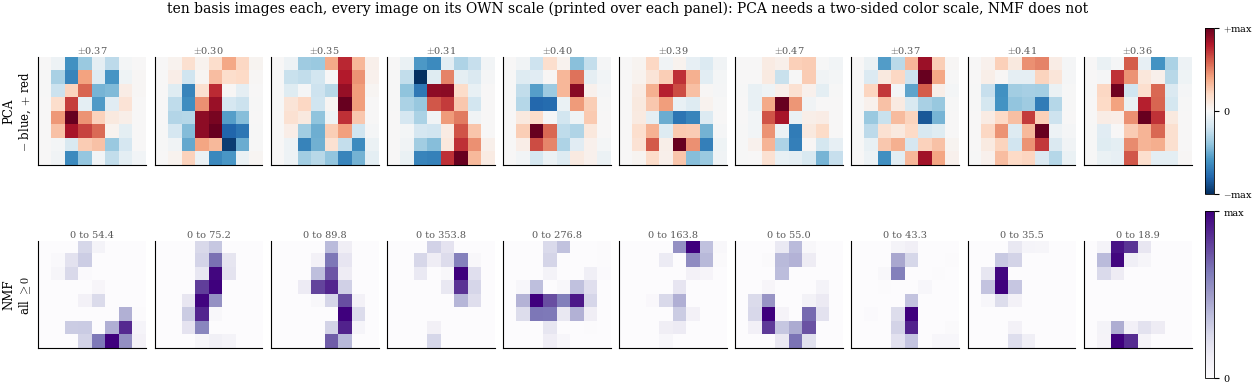

In [11]:
k_nm = 10                                                  # <-- CHANGE ME
pca_nm = PCA(n_components=k_nm).fit(Xd)
nmf_nm = NMF(n_components=k_nm, init="nndsvda", max_iter=1200, random_state=0).fit(Xd)


def concentration(B, frac=0.9):
    "how many entries carry `frac` of a basis image's mass -- smaller means more local"
    out = []
    for b in np.abs(np.asarray(B, float)):
        s = np.sort(b)[::-1]
        out.append(int(np.searchsorted(np.cumsum(s) / s.sum(), frac)) + 1)
    return float(np.mean(out))


W_nm = nmf_nm.transform(Xd)
err_nmf = ((Xd - W_nm @ nmf_nm.components_) ** 2).sum(axis=1).mean()
err_pca = ((Xd - pca_nm.inverse_transform(pca_nm.transform(Xd))) ** 2).sum(axis=1).mean()
print("                                             PCA      NMF")
print(f"share of basis entries that are negative   {100 * (pca_nm.components_ < 0).mean():5.1f}%   "
      f"{100 * (nmf_nm.components_ < 0).mean():5.1f}%")
print(f"pixels holding 90% of a basis image (/64)  {concentration(pca_nm.components_):5.1f}    "
      f"{concentration(nmf_nm.components_):5.1f}")
print(f"mean squared reconstruction error at k={k_nm}  {err_pca:5.1f}    {err_nmf:5.1f}"
      f"   <- NMF pays {err_nmf / err_pca:.2f}x for the constraint")
print(f"share of the codes that are exactly zero   {100 * (pca_nm.transform(Xd) == 0).mean():5.1f}%   "
      f"{100 * (W_nm == 0).mean():5.1f}%")

worst_nm = []
for sa, sb in ((0, 1), (2, 3), (4, 5)):
    na = NMF(n_components=k_nm, init="random", max_iter=1200, random_state=sa).fit(Xd)
    nb_ = NMF(n_components=k_nm, init="random", max_iter=1200, random_state=sb).fit(Xd)
    S = np.array([unit(c) for c in na.components_]) @ np.array([unit(c) for c in nb_.components_]).T
    worst_nm.append(S.max(axis=1).min())                  # best match for the worst-matched one
worst_nm = np.array(worst_nm)
print(f"\nthree PAIRS of runs from different random starts -- cosine similarity of the")
print(f"worst-matched component pair: {np.array2string(worst_nm.round(3))}, mean {worst_nm.mean():.3f}")

fig, axes = plt.subplots(2, k_nm, figsize=(12.6, 3.9))
for j in range(k_nm):
    b = pca_nm.components_[j]
    mb = np.abs(b).max()                                   # this panel's own scale
    axes[0, j].imshow(b.reshape(8, 8), cmap="RdBu_r", vmin=-mb, vmax=mb)
    axes[0, j].set_title(f"$\\pm${mb:.2f}", fontsize=7, color="0.35", pad=2.5)
    c = nmf_nm.components_[j]
    mc = c.max()
    axes[1, j].imshow(c.reshape(8, 8), cmap="Purples", vmin=0, vmax=mc)
    axes[1, j].set_title(f"0 to {mc:.1f}", fontsize=7, color="0.35", pad=2.5)
    for r in (0, 1):
        axes[r, j].set_xticks([]); axes[r, j].set_yticks([]); axes[r, j].grid(False)
axes[0, 0].set_ylabel("PCA\n$-$ blue, $+$ red", fontsize=8.5)
axes[1, 0].set_ylabel("NMF\nall $\\geq 0$", fontsize=8.5)
for r, (cmap_r, lo, ticks, tlab) in enumerate((("RdBu_r", -1, [-1, 0, 1], ["$-$max", "0", "$+$max"]),
                                               ("Purples", 0, [0, 1], ["0", "max"]))):
    cb = fig.colorbar(mpl.cm.ScalarMappable(norm=mpl.colors.Normalize(lo, 1), cmap=cmap_r),
                      ax=axes[r, :], fraction=0.018, pad=0.012, ticks=ticks)
    cb.ax.set_yticklabels(tlab, fontsize=7)
    cb.outline.set_linewidth(0.6)
fig.suptitle("ten basis images each, every image on its OWN scale (printed over each panel): "
             "PCA needs a two-sided color scale, NMF does not", fontsize=10)
plt.show()

## Recap & exercises

**Recap.** The thread was *variance is not always the question you are asking*.

* **The curse is why we reduce.** With 500 points, the nearest neighbor is $0.001$ of the distance
  to the farthest at $d=1$ but $0.616$ at $d=50$ and $0.788$ at $d=200$. Distances **flatten**
  &mdash; at $d=50$ the farthest point is only $1.62\times$ farther, not $1\times$.
* **PCA is three steps and one matrix.** Center, build $C=\tfrac1n\tilde X^\top\tilde X$,
  eigendecompose. On four points it came out exactly: $\lambda=(4,1)$, PC1 $=(1,1)/\sqrt2$, $80\%$
  of the variance in PC1.
* **The SVD is the same answer, computed better.** $\sigma=(4,2)$ there, and $\sigma_k^2/n=\lambda_k$.
  Watch the divisor: scikit-learn's `explained_variance_` is $\sigma_k^2/(n-1)$, a factor
  $n/(n-1)$ bigger. The **ratios** are untouched.
* **Maximum variance and minimum reconstruction are one fit**, because the two add to a constant
  &mdash; measured to $2.66\times10^{-15}$ over every direction. And PCA is *not* regression: on our
  cloud the two lines sit $14.20^\circ$ apart.
* **The cost of keeping $k$ components is the variance you dropped**, $\sum_{j>k}\lambda_j$, exactly
  (to $10^{-13}$): $391.7947$ per digit image at $k=8$.
* **PCA has no units.** The same people, height in meters or centimeters, give PC1 shares of
  $100.00\%$ and $86.25\%$. Standardize unless the features already share units &mdash; and then
  notice that it moved the digits' $90\%$ point from 21 components to 31.
* **Break 1 &mdash; labels.** On the cigars PC1 keeps $99.24\%$ of the variance and classifies at
  $0.5417$, the 76th percentile of shuffled-label noise ($0.5342\pm0.0106$), i.e. nothing. LDA's one
  component reaches $0.9810\pm0.0111$ held out. "Run PCA first, then classify" can quietly cost you
  everything.
* **LDA is $S_W^{-1}(\boldsymbol\mu_1-\boldsymbol\mu_0)$**, which is Session&nbsp;05's classifier
  direction &mdash; the same vector to one ulp ($1-|\cos|=1.1\times10^{-16}$). It gives at most
  $K-1$ directions, and it is blind to classes that differ in shape rather than mean ($0.5675$ in
  sample, where QDA gets $0.8974\pm0.0207$ held out).
* **Break 2 &mdash; per-feature noise.** Factor analysis models the data instead of rotating it, and
  its diagonal $\Psi$ makes it nearly immune to a rescaled feature: over 20 draws PCA's direction
  moved $6.993^\circ$ on average ($5.561$ to $8.024$) and factor analysis's $0.0024^\circ$ ($0.0004$
  to $0.0052$, positive on every draw) &mdash; a factor of $2867$, PCA further on 20 of 20 draws.
  The price: loadings are defined only up to a rotation, so a *named* factor was chosen from a
  continuum. The lecture quotes one fixed draw, seed 7's $8.280^\circ$, which lands above all 20
  of these &mdash; a seed, not a discrepancy.
* **Break 3 &mdash; non-negativity.** NMF's constraint is the method: $0.0\%$ negative basis entries
  against PCA's $46.7\%$, $13.2$ pixels per basis image against $31.2$ &mdash; parts instead of a
  holistic mixture &mdash; paid for with $1.30\times$ the reconstruction error and a non-convex
  objective.
* **Two habits.** Never compare components by subtraction (signs are arbitrary): compare $|\cos|$,
  and test collinearity with $1-|\cos|$, because $\arccos$ cannot resolve better than about
  $10^{-6}$ degrees. And never score a projection against $0.5$ when the statistic is a maximum
  over thresholds: shuffle the labels and measure the ceiling.

**Exercises.**
1. In &sect;1, keep $d=50$ fixed and vary $n$ over $50,\,500,\,5000$. Does more data make the
   nearest/farthest ratio better or worse? Explain what that means for $k$-NN.
2. In &sect;3, replace the cloud with one whose covariance is
   $\left(\begin{smallmatrix}1&0\\0&1\end{smallmatrix}\right)$. What happens to the variance curve,
   and what does `PCA` return for PC1? Why is any answer as good as any other?
3. In &sect;5, scale *weight* by $1/100$ (so it is in units of 100&nbsp;kg) instead of scaling
   height. Predict PC1 before you run it, then check.
4. In &sect;6, shrink `gap` in `make_cigars` until LDA's held-out accuracy falls below $0.90$. At
   that separation, does PC1's in-sample score rise above the noise ceiling?
5. In &sect;8, set `rescale_fa = 1.0`. Both angles should collapse; verify that they do, and say why
   that is the right control experiment for the claim in the table.
6. In &sect;10, run NMF with `k_nm = 20` and with `k_nm = 3`. Does the localization measure (pixels
   per basis image) go up or down with $k$, and why?

*Next, notebook&nbsp;11b &mdash; **t-SNE and UMAP**: what to do when a flat subspace is not
enough, and how to read a nonlinear map without over-reading it.*